# 02 - Preprocess & Split

Roadmap **Bước 1.2–1.3**:
- Định dạng đầu vào `state: <State> question: <question>`, đáp án chuẩn hoá `yes` / `no`
- Đo độ dài sau tokenize (tokenizer Flan-T5, dùng chung cho M1 và M2) để chốt `max_source_len` / `max_target_len`
- Chia train / val / test 80 / 10 / 10 theo `question_group` (`GroupShuffleSplit`, `random_state=42`)
- (Tuỳ chọn) bổ sung `questions_aux` vào train

Đầu ra: `data/processed/{train,val,test,train_aux}.jsonl` và `data/processed/split_meta.json`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from transformers import AutoTokenizer

from legal_qa.data import HousingQA, write_json, write_jsonl
from legal_qa.data.housingqa import load_questions
from legal_qa.data.preprocessing import MODEL_NAME, qa_key, resolve_duplicates, to_record, token_lengths
from legal_qa.data.splitting import aux_train_extension, check_no_leakage, group_split, split_summary
from legal_qa.paths import FIGURES_DIR, PROCESSED_DIR, TABLES_DIR

SEED = 42
VAL_SIZE = TEST_SIZE = 0.1

[transformers] PyTorch was not found. Models won't be available and only tokenizers, configuration and file/data utilities can be used.


In [3]:
Q = load_questions("questions")
A = load_questions("questions_aux")
kept, dropped = resolve_duplicates(Q)
print(f"questions: {len(Q)} -> giữ {len(kept)}, bỏ {len(dropped)} dòng có nhãn mâu thuẫn")
pd.DataFrame(dropped)[["idx", "state", "question_group", "answer"]]

[housing_qa] load_dataset('questions') failed (RuntimeError: Dataset scripts are no longer supported, but found housing_qa.py) -> using raw zip


[housing_qa] load_dataset('questions_aux') failed (RuntimeError: Dataset scripts are no longer supported, but found housing_qa.py) -> using raw zip
questions: 6853 -> giữ 6844, bỏ 9 dòng có nhãn mâu thuẫn


,idx,state,question_group,answer
0,9206,Connecticut,196,No
1,9207,Connecticut,196,No
2,9208,Connecticut,196,Yes
3,9209,District of Columbia,196,Yes
4,9210,District of Columbia,196,No
5,9211,District of Columbia,196,No
6,9218,Washington,196,Yes
7,9219,Washington,196,No
8,9220,Washington,196,No


## 1. Định dạng đầu vào / đầu ra

In [4]:
records = [to_record(r, "questions") for r in kept]
print(json.dumps({k: v for k, v in records[0].items() if k != "statutes"}, indent=2, ensure_ascii=False))

{
  "id": "q-0",
  "source": "questions",
  "state": "Alabama",
  "question_group": 69,
  "question": "Is there a state/territory law regulating residential evictions?",
  "answer": "yes",
  "input_text": "state: Alabama question: Is there a state/territory law regulating residential evictions?",
  "target_text": "yes",
  "gold_statute_idx": [
    431263
  ],
  "original_question": "Is there a state/territory law regulating residential evictions?",
  "caveats": []
}


## 2. Tokenization và độ dài

In [5]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
aux_preview = [to_record(r, "questions_aux") for r in resolve_duplicates(A)[0]]

src_len = token_lengths([r["input_text"] for r in records + aux_preview], tokenizer)
tgt_len = token_lengths([r["target_text"] for r in records], tokenizer)
print("yes ->", tokenizer("yes").input_ids, "| no ->", tokenizer("no").input_ids)
pd.DataFrame({"source_tokens": pd.Series(src_len).describe(percentiles=[0.5, 0.95, 0.99]),
              "target_tokens": pd.Series(tgt_len).describe(percentiles=[0.5, 0.95, 0.99])}).round(1)

yes -> [4273, 1] | no -> [150, 1]


,source_tokens,target_tokens
count,16034.0,6844.0
mean,35.8,2.0
std,16.5,0.0
min,17.0,2.0
50%,32.0,2.0
95%,69.0,2.0
99%,109.0,2.0
max,121.0,2.0


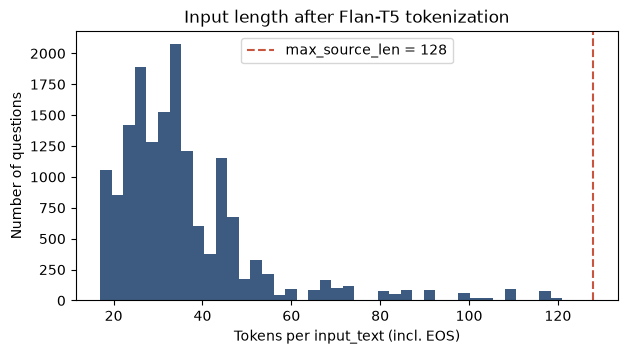

In [6]:
MAX_SOURCE_LEN = 128
MAX_TARGET_LEN = 4
assert src_len.max() <= MAX_SOURCE_LEN and tgt_len.max() <= MAX_TARGET_LEN

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(src_len, bins=40, color="#3D5A80")
ax.axvline(MAX_SOURCE_LEN, color="#C8553D", ls="--", label=f"max_source_len = {MAX_SOURCE_LEN}")
ax.set_xlabel("Tokens per input_text (incl. EOS)")
ax.set_ylabel("Number of questions")
ax.set_title("Input length after Flan-T5 tokenization")
ax.legend()
fig.savefig(FIGURES_DIR / "source_token_length.png", dpi=150, bbox_inches="tight")
plt.show()

**Nhận xét:** đầu vào dài nhất 121 token (tính cả `questions_aux`), nên `max_source_len = 128` không cắt câu nào. Đáp án luôn là 1 token + EOS, `max_target_len = 4` để dư cho M1 sinh chuỗi lạ.

## 3. Chia tập theo `question_group`

In [7]:
splits = group_split(records, val_size=VAL_SIZE, test_size=TEST_SIZE, seed=SEED)
check_no_leakage(splits)
summary = split_summary(splits)
summary

,split,n_questions,share,n_groups,n_states,n_yes,n_no,yes_ratio
0,train,5505,0.804,180,48,1963,3542,0.357
1,val,650,0.095,22,48,191,459,0.294
2,test,689,0.101,23,48,257,432,0.373


**Nhận xét:** theo số câu, tỉ lệ là 80,4 / 9,5 / 10,1; `check_no_leakage` xác nhận không có `question_group`, câu hỏi hay `id` nào xuất hiện ở hai tập. Tập val có ít Yes hơn train (29,4% so với 35,7%).

In [8]:
# Val/test chỉ có ~22 nhóm nên tỉ lệ Yes dao động theo seed.
seed_scan = pd.DataFrame([
    {"seed": s, **split_summary(group_split(records, VAL_SIZE, TEST_SIZE, s)).set_index("split")["yes_ratio"].to_dict()}
    for s in range(10)
] + [{"seed": SEED, **summary.set_index("split")["yes_ratio"].to_dict()}]).drop_duplicates("seed").set_index("seed")
seed_scan["max_gap"] = (seed_scan[["val", "test"]].sub(seed_scan["train"], axis=0)).abs().max(axis=1)
seed_scan.round(3)

,train,val,test,max_gap
seed,,,,
0,0.362,0.343,0.289,0.073
1,0.349,0.238,0.481,0.132
2,0.335,0.403,0.438,0.103
3,0.353,0.427,0.275,0.078
4,0.341,0.424,0.374,0.083
5,0.352,0.334,0.377,0.025
6,0.351,0.308,0.403,0.052
7,0.336,0.458,0.390,0.122
8,0.345,0.518,0.252,0.173


**Nhận xét:** val/test chỉ có 22–23 nhóm, mỗi nhóm có tới 43 câu cùng xu hướng đáp án, nên đổi seed nào cũng lệch vài điểm % (trung vị chênh lệch lớn nhất khoảng 8 điểm). Seed 42 lệch 6,3 điểm, thấp hơn trung vị, nên **giữ seed 42** và ghi chú vào report thay vì chọn seed theo kết quả.

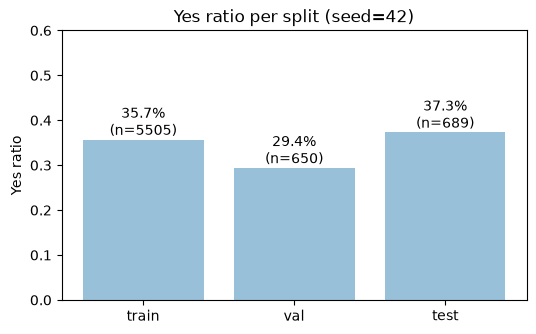

In [9]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(summary["split"], summary["yes_ratio"], color="#98C1D9")
ax.bar_label(bars, labels=[f"{v:.1%}\n(n={n})" for v, n in zip(summary["yes_ratio"], summary["n_questions"])])
ax.set_ylim(0, 0.6)
ax.set_ylabel("Yes ratio")
ax.set_title(f"Yes ratio per split (seed={SEED})")
fig.savefig(FIGURES_DIR / "split_label_balance.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Bổ sung `questions_aux` vào train (tuỳ chọn)

`questions_aux` chứa toàn bộ `questions` và thêm câu ở các bang khác, cùng 226 nhóm. Chỉ lấy (bang, câu hỏi) **chưa có trong `questions`** và thuộc **nhóm của train**, nên không có câu hỏi nào của val/test lọt vào. Các dòng này không có `statute_idx`, lưu riêng ở `train_aux.jsonl`, M1 và M2 phải dùng cùng một lựa chọn (có hoặc không có aux).

In [10]:
train_groups = {r["question_group"] for r in splits["train"]}
aux_raw = aux_train_extension(A, train_groups, exclude_keys={qa_key(r) for r in Q})
train_aux = [to_record(r, "questions_aux") for r in aux_raw]

check_no_leakage({"train_aux": train_aux, "val": splits["val"], "test": splits["test"]})
assert not {(r["state"], r["question"]) for r in train_aux} & {(r["state"], r["question"]) for r in splits["train"]}
split_summary({"train": splits["train"], "train_aux": train_aux}).assign(
    n_states_new=[0, len({r["state"] for r in train_aux} - {r["state"] for r in records})]
)

,split,n_questions,share,n_groups,n_states,n_yes,n_no,yes_ratio,n_states_new
0,train,5505,0.746,180,48,1963,3542,0.357,0
1,train_aux,1877,0.254,179,42,614,1263,0.327,7


**Nhận xét:** thêm 1.877 câu (7 bang mới) cho train. Đây là tuỳ chọn: nếu dùng thì M1 và M2 phải cùng dùng `HousingQA().splits(include_aux=True)`.

## 5. Lưu

In [11]:
for name, rows in {**splits, "train_aux": train_aux}.items():
    n = write_jsonl(rows, PROCESSED_DIR / f"{name}.jsonl")
    print(f"{name:10s} -> {n} dòng")

summary_all = split_summary({**splits, "train_aux": train_aux})
summary_all.to_csv(TABLES_DIR / "split_summary.csv", index=False)
write_json({
    "dataset": "reglab/housing_qa",
    "seed": SEED,
    "split_by": "question_group",
    "sizes": {"val": VAL_SIZE, "test": TEST_SIZE},
    "input_format": "state: {state} question: {question}",
    "labels": ["yes", "no"],
    "tokenizer": MODEL_NAME,
    "max_source_len": MAX_SOURCE_LEN,
    "max_target_len": MAX_TARGET_LEN,
    "dropped_conflicting_ids": [r["idx"] for r in dropped],
    "groups": {name: sorted({r["question_group"] for r in rows}) for name, rows in splits.items()},
    "summary": summary_all.to_dict(orient="records"),
}, PROCESSED_DIR / "split_meta.json")

train      -> 5505 dòng
val        -> 650 dòng
test       -> 689 dòng
train_aux  -> 1877 dòng


In [12]:
loaded = HousingQA().splits(include_aux=True)
print({k: len(v) for k, v in loaded.items()})

{'train': 7382, 'val': 650, 'test': 689}
